# The final pipeline: one ladder from first features to neural networks

Earlier notebooks built the model step by step. This notebook replays every step on **one** evaluation setup, so the numbers are directly comparable:

* June + September 2026 detailed listings, after the shared pre-check (7,039 priced listings).
* LightGBM, the same settings throughout.
* Host-grouped 5-fold cross-validation: no host appears on both sides of a split.
* Text and photo features are fitted inside each fold, on training rows only.

It then chooses the model the calculator uses, measures its price range, and exports it to the browser.

In [1]:
import json, sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.metrics import mean_absolute_error, r2_score
import lightgbm as lgb

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DATA, OUT, CACHE, SEED = Path("../data"), Path("../interface"), Path("../data/raw/cache"), 42
sys.path.insert(0, "../src"); sys.path.insert(0, "../scripts")
import pricing_features as pf
import enriched_features as ef
from download_photos import photo_path
_js = (OUT / "data.js").read_text(); BUNDLE = json.loads(_js[_js.index("{"): _js.rindex("}") + 1])
ZONES = BUNDLE["quarterly"]["zones"]["centers_km"]
A, X, y, groups = ef.build_merged_matrix(DATA, ZONES)
official = pd.read_csv(DATA / "neighbourhoods.csv")["neighbourhood"]
H = pf.model_neighbourhoods(official)
PROPS = sorted(set(ef.PROPERTY_GROUPS.values())) + ["other"]
COLS = {
    "snapshot": list(pf.build_features(A.head(3), H).columns),
    "time_zone": ["q_sep", "tenure_q", "days_since_review", "ring_core", "ring_inner", "ring_outer"] + [f"zone_{z}" for z in range(len(ZONES))],
    "detailed": list(ef.detailed_features(A.head(3), PROPS).columns),
    "location": list(ef.landmark_features(A.head(3)).columns) + ["supply_300m", "supply_1km"],
    "age_night": ["months_since_first_review"] + [f"quote_dow_{d}" for d in range(7)],
}
assert sum(len(v) for v in COLS.values()) == X.shape[1], (sum(len(v) for v in COLS.values()), X.shape[1])
LGB = dict(n_estimators=900, learning_rate=0.03, num_leaves=31, min_child_samples=20, subsample=0.8, subsample_freq=1,
           colsample_bytree=0.6, reg_lambda=1.0, random_state=SEED, verbose=-1)
FOLDS = list(GroupKFold(5).split(X, y, groups))
print(X.shape, {k: len(v) for k, v in COLS.items()})

(7039, 141) {'snapshot': 43, 'time_zone': 14, 'detailed': 58, 'location': 18, 'age_night': 8}


## 1. Text and photo inputs

* **Classic text:** TF-IDF of the description (16 components) and of the 30 most recent reviews before each snapshot (24 components), plus 12 review-aspect shares. Price words are removed from reviews, because comments on value are a reaction to the price.
* **Neural text:** `BAAI/bge-small-en-v1.5` sentence embeddings (384 numbers) of the description and of the recent reviews, compressed to 16 numbers each by PCA fitted on the training fold.
* **Neural photo:** `CLIP ViT-B/32` embeddings (512 numbers) of the cover photo, compressed to 16. Listings whose photo no longer exists stay missing.

The embeddings come from the cache written by `boston_airbnb_phase3_text_market.ipynb`, computed on the same rows in the same order.

In [2]:
REVTXT = pd.Series("", index=A.index); ASP = pd.DataFrame(index=A.index)
for q, date in [("2026Q2", "2026-06-15"), ("2026Q3", "2026-09-19")]:
    rv = pd.read_csv(DATA / "raw" / q / "reviews.csv.gz")
    t, asp = ef.review_text_by_listing(rv, date)
    m = (A["quarter"] == q).values
    REVTXT[m] = A.loc[m, "id"].map(t).fillna("").values
    ASP = ASP.combine_first(pd.DataFrame(asp.reindex(A.loc[m, "id"]).values, index=A.index[m], columns=asp.columns))
DESC = A["description"].fillna("").str.replace(r"<br\s*/?>", " ", regex=True)
STOP = list(ENGLISH_STOP_WORDS | set(ef.PRICE_WORDS))
E_DESC, E_REV, E_IMG = (np.load(CACHE / f"{n}.npy") if (CACHE / f"{n}.npy").exists() else None for n in ["bge_desc", "bge_reviews", "clip_photos"])
for n, E in [("bge description", E_DESC), ("bge reviews", E_REV), ("CLIP photo", E_IMG)]:
    print(n, "missing from cache" if E is None else E.shape)
    assert E is None or len(E) == len(A)
has_rev = (REVTXT.str.len() > 0).values
has_photo = np.array([photo_path(u).exists() for u in A["picture_url"]])

def tfidf_svd(text, a, b, k, prefix):
    v = TfidfVectorizer(min_df=10, max_features=30000, ngram_range=(1, 2), sublinear_tf=True, stop_words=STOP)
    Xa, Xb = v.fit_transform(text.iloc[a]), v.transform(text.iloc[b])
    s = TruncatedSVD(k, random_state=SEED).fit(Xa)
    out = np.zeros((len(text), k)); out[a], out[b] = s.transform(Xa), s.transform(Xb)
    return pd.DataFrame(out, index=text.index, columns=[f"{prefix}{i}" for i in range(k)])

def pca_block(E, a, b, k, prefix, mask):
    p = PCA(k, random_state=SEED).fit(E[a[mask[a]]])
    out = np.full((len(E), k), np.nan)
    for idx in (a, b):
        ok = idx[mask[idx]]; out[ok] = p.transform(E[ok])
    return pd.DataFrame(out, index=A.index, columns=[f"{prefix}{i}" for i in range(k)])

bge description (7039, 384)
bge reviews (7039, 384)
CLIP photo (7039, 512)


## 2. The ladder

Each rung adds one group of inputs to everything above it. The last row tests whether the neural networks can *replace* the classic text features rather than add to them.

In [3]:
RUNGS = ["1. Listing basics + time and zone", "2. + detailed attributes", "3. + landmarks and supply",
         "4. + listing age and night of week", "5. + text, classic NLP", "6. + text, neural network (bge-small)",
         "7. + photo, neural network (CLIP)", "alt. rung 4 + neural text and photo, no classic NLP"]
TAB = {RUNGS[0]: COLS["snapshot"] + COLS["time_zone"], RUNGS[1]: COLS["detailed"], RUNGS[2]: COLS["location"], RUNGS[3]: COLS["age_night"]}
rows, imps = [], []
for k, (a, b) in enumerate(FOLDS):
    text_classic = pd.concat([tfidf_svd(DESC, a, b, 16, "desc_tf_"), ASP, tfidf_svd(REVTXT, a, b, 24, "rev_tf_")], axis=1)
    nn_text = pd.concat([pca_block(E_DESC, a, b, 16, "desc_bge_", np.ones(len(A), bool)), pca_block(E_REV, a, b, 16, "rev_bge_", has_rev)], axis=1) if E_DESC is not None else None
    nn_img = pca_block(np.nan_to_num(E_IMG), a, b, 16, "img_clip_", has_photo) if E_IMG is not None else None
    cum, sets = [], {}
    for r in RUNGS[:4]:
        cum = cum + TAB[r]; sets[r] = X[cum]
    sets[RUNGS[4]] = pd.concat([sets[RUNGS[3]], text_classic], axis=1)
    if nn_text is not None:
        sets[RUNGS[5]] = pd.concat([sets[RUNGS[4]], nn_text], axis=1)
    if nn_img is not None:
        sets[RUNGS[6]] = pd.concat([sets.get(RUNGS[5], sets[RUNGS[4]]), nn_img], axis=1)
    if nn_text is not None and nn_img is not None:
        sets[RUNGS[7]] = pd.concat([sets[RUNGS[3]], nn_text, nn_img], axis=1)
    for r, Xs in sets.items():
        m = lgb.LGBMRegressor(**LGB).fit(Xs.iloc[a], y[a]); p = m.predict(Xs.iloc[b])
        rows.append({"fold": k, "rung": r, "MAE": mean_absolute_error(np.exp(y[b]), np.exp(p)), "R2_log": r2_score(y[b], p), "n_features": Xs.shape[1]})
        if r == list(sets)[-2 if RUNGS[7] in sets else -1]:
            imps.append(pd.Series(m.booster_.feature_importance("gain"), Xs.columns))
cv = pd.DataFrame(rows)
order = [r for r in RUNGS if r in set(cv["rung"])]
piv = cv.pivot(index="fold", columns="rung", values="MAE")[order]
main = [r for r in order if not r.startswith("alt")]
ladder = pd.DataFrame({"CV MAE ($/night)": piv.mean(), "± std": piv.std(), "R² (log)": cv.groupby("rung")["R2_log"].mean()[order],
                       "features": cv.groupby("rung")["n_features"].first()[order]})
chg = piv[main].diff(axis=1)
ladder["change vs previous rung"] = chg.mean().reindex(order)
ladder["folds improved"] = (chg < 0).sum().reindex(order).where(ladder.index != main[0])
if RUNGS[7] in order:
    alt_d = piv[RUNGS[7]] - piv[RUNGS[3]]
    ladder.loc[RUNGS[7], "change vs previous rung"] = alt_d.mean(); ladder.loc[RUNGS[7], "folds improved"] = (alt_d < 0).sum()
ladder.round(3)

,CV MAE ($/night),± std,R² (log),features,change vs previous rung,folds improved
rung,,,,,,
1. Listing basics + time and zone,112.598,8.860,0.663,57,NaN,NaN
2. + detailed attributes,87.124,7.037,0.788,115,-25.474,5.0
3. + landmarks and supply,86.814,5.810,0.787,133,-0.310,4.0
4. + listing age and night of week,84.738,6.345,0.795,141,-2.076,5.0
"5. + text, classic NLP",83.703,6.602,0.798,195,-1.035,5.0
"6. + text, neural network (bge-small)",83.914,6.339,0.797,227,0.212,2.0
"7. + photo, neural network (CLIP)",84.375,6.372,0.794,243,0.460,0.0
"alt. rung 4 + neural text and photo, no classic NLP",84.542,5.556,0.797,189,-0.196,3.0


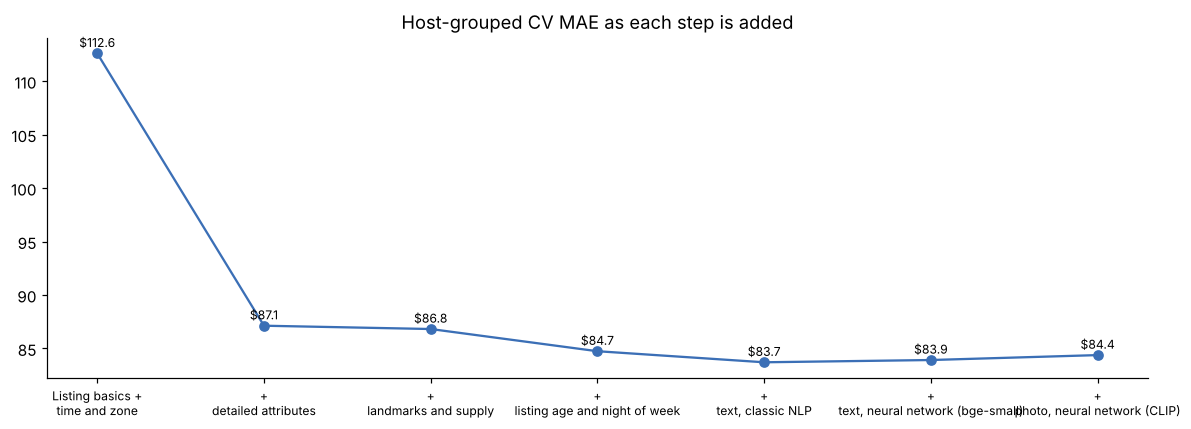

,% of LightGBM split gain (full model)
Detailed attributes,40.1
Listing basics,31.5
"Text, classic",9.4
Landmarks and supply,6.5
"Text, neural",5.4
"Photo, neural",4.6
Time and zone,1.4
Listing age and night of week,0.9
other,0.1


In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(range(len(main)), piv[main].mean().values, marker="o", color="#3b6fb6")
for i, v in enumerate(piv[main].mean().values): ax.text(i, v + 0.6, f"${v:.1f}", ha="center", fontsize=8)
ax.set_xticks(range(len(main)), [r.split(". ", 1)[1].replace("+ ", "+\n") for r in main], fontsize=8)
ax.set_title("Host-grouped CV MAE as each step is added"); plt.tight_layout(); plt.show()
gain = pd.concat(imps, axis=1).mean(axis=1)
def fam(c):
    for pre, f in [("desc_tf_", "Text, classic"), ("rev_tf_", "Text, classic"), ("asp_", "Text, classic"), ("desc_bge_", "Text, neural"),
                   ("rev_bge_", "Text, neural"), ("img_clip_", "Photo, neural")]:
        if c.startswith(pre): return f
    for f, cols in [("Listing basics", COLS["snapshot"]), ("Time and zone", COLS["time_zone"]), ("Detailed attributes", COLS["detailed"]),
                    ("Landmarks and supply", COLS["location"]), ("Listing age and night of week", COLS["age_night"])]:
        if c in cols: return f
    return "other"
fam_gain = (gain.groupby(gain.index.map(fam)).sum() / gain.sum() * 100).sort_values(ascending=False)
fam_gain.round(1).to_frame("% of LightGBM split gain (full model)")

## 3. Choosing the model for the calculator

The decision rule is fixed in advance. The overfitting check added pure-noise columns to the same model: the largest gain one produced was about $1.07 a night (in 4 of 5 folds). So a text or photo step counts as a real gain only if it lowers the CV error by **more than the largest noise gain, in at least 4 of 5 folds**. A smaller gain is called *within the noise range*: possibly real, but not proven on 7,000 listings. A step that passes would still need its model running in the browser: about 30 MB for bge-small, and about 90 MB for CLIP.

In [5]:
_ov = open(OUT / "data.js").read()
NOISE_MAX = json.loads(_ov[_ov.index("{"): _ov.rindex("}") + 1])["overfit"]["noise"]["max_gain"]
print(f"largest gain from a pure-noise feature: ${NOISE_MAX:.2f}")
def verdict(r):
    ch, folds = ladder.loc[r, "change vs previous rung"], ladder.loc[r, "folds improved"]
    if ch < -NOISE_MAX and folds >= 4: return "clears noise"
    if ch < 0 and folds >= 3: return "within noise range"
    return "no gain"
nn_steps = [r for r in [RUNGS[5], RUNGS[6]] if r in ladder.index]
decision = {r: verdict(r) for r in [RUNGS[4]] + nn_steps}
DEPLOY = RUNGS[3]
print("tabular model (rung 4):", f"${ladder.loc[DEPLOY, 'CV MAE ($/night)']:.2f}")
print("best rung overall:", ladder["CV MAE ($/night)"].idxmin(), f"${ladder['CV MAE ($/night)'].min():.2f}")
for r, d in decision.items():
    print(f"{r}: {d}  (change {ladder.loc[r, 'change vs previous rung']:+.2f}, {int(ladder.loc[r, 'folds improved'])}/5 folds)")

largest gain from a pure-noise feature: $1.07
tabular model (rung 4): $84.74
best rung overall: 5. + text, classic NLP $83.70
5. + text, classic NLP: within noise range  (change -1.04, 5/5 folds)
6. + text, neural network (bge-small): no gain  (change +0.21, 2/5 folds)
7. + photo, neural network (CLIP): no gain  (change +0.46, 0/5 folds)


**Why the calculator runs the tabular model (rung 4).** Text and photos can't be scored for a new host's listing without running the language and image models in the page, and their measured gains are no larger than what noise produces (see the table above). Rung 4 uses only what a host can type into a form. Its error is the honest expectation for the calculator.

## 4. Price range and the final fit

In [6]:
XD = X[sum([TAB[r] for r in RUNGS[:4]], [])]
oof = np.zeros(len(y))
for a, b in FOLDS:
    oof[b] = lgb.LGBMRegressor(**LGB).fit(XD.iloc[a], y[a]).predict(XD.iloc[b])
res = y - oof
band = [float(np.quantile(res, 0.10)), float(np.quantile(res, 0.90))]
print(f"out-of-fold MAE ${mean_absolute_error(np.exp(y), np.exp(oof)):.2f}, R² (log) {r2_score(y, oof):.3f}")
print(f"80% range: prediction × {np.exp(band[0]):.2f} to × {np.exp(band[1]):.2f}")
final = lgb.LGBMRegressor(**LGB).fit(XD, y)

out-of-fold MAE $84.74, R² (log) 0.801
80% range: prediction × 0.67 to × 1.49


In [7]:
MISSING = {"None": 0, "Zero": 1, "NaN": 2}
def convert(tree):
    # pre-order arrays: f = feature (-1 leaf), x = threshold or leaf value, d = default-left flag, m = missing type
    f, x, d, m = [], [], [], []
    def rec(n):
        if "leaf_value" in n:
            f.append(-1); x.append(float(f"{n['leaf_value']:.8g}")); d.append(0); m.append(0); return
        assert n["decision_type"] == "<="
        f.append(n["split_feature"]); x.append(float(n["threshold"])); d.append(int(n["default_left"])); m.append(MISSING[n["missing_type"]])
        rec(n["left_child"]); rec(n["right_child"])
    rec(tree["tree_structure"])
    return {"f": f, "x": x, "d": d, "m": m}
dump = final.booster_.dump_model()
trees = [convert(t) for t in dump["tree_info"]]
ref = XD.sample(200, random_state=1)
models = {"final": {"trees": trees, "features": list(XD.columns)},
          "final_reference": {"X": [[None if pd.isna(v) else float(v) for v in r] for r in ref.values], "pred": [float(v) for v in final.predict(ref)]}}
(OUT / "models.js").write_text("window.PRICING_MODELS = " + json.dumps(models, separators=(",", ":")) + ";\n")
print(len(trees), "trees,", sum(len(t["f"]) for t in trees), "nodes ->", f"{(OUT / 'models.js').stat().st_size / 1e6:.2f} MB")

900 trees, 54900 nodes -> 1.50 MB


## 5. Calculator inputs and parity cases

The browser rebuilds all 141 features from a form. To prove it matches Python, 40 random listings are built as raw rows. Each goes through the same pre-check and feature code as the training data, and the expected features and prices are saved for `scripts/verify_js.js`.

In [8]:
SNAPDATE = {"2026Q2": "2026-06-16", "2026Q3": "2026-09-20"}
REP_TYPE = {g: t for t, g in reversed(list(ef.PROPERTY_GROUPS.items()))}; REP_TYPE["other"] = "Tiny home"
AMEN_LABEL = {"am_free_parking": "Free parking on premises", "am_paid_parking": "Paid parking garage off premises", "am_washer_in_unit": "Free washer – In unit",
    "am_dryer": "Dryer", "am_dishwasher": "Dishwasher", "am_central_ac": "Central air conditioning", "am_any_ac": "Air conditioning", "am_gym": "Gym",
    "am_pool": "Pool", "am_hot_tub": "Hot tub", "am_elevator": "Elevator", "am_workspace": "Dedicated workspace", "am_self_checkin": "Self check-in",
    "am_balcony_patio": "Patio or balcony", "am_view": "City skyline view", "am_kitchen": "Kitchen", "am_bathtub": "Bathtub", "am_fireplace": "Indoor fireplace",
    "am_ev_charger": "EV charger", "am_pets": "Pets allowed", "am_long_term": "Long term stays allowed", "am_luggage": "Luggage dropoff allowed",
    "am_crib": "Crib", "am_private_entry": "Private entrance", "am_backyard": "Backyard", "am_bbq": "BBQ grill", "am_tv": "TV", "am_streaming": "Netflix",
    "am_game_console": "Game console", "am_sound_system": "Bluetooth sound system"}
KW_WORD = {"kw_parking": "parking", "kw_luxury": "modern", "kw_view": "view", "kw_amenities": "gym"}
SCORES = ["rating", "accuracy", "cleanliness", "checkin", "communication", "location", "value"]
hood_ll = A.groupby("neighbourhood")[["latitude", "longitude"]].median()

def raw_row(L, i):
    scraped = pd.Timestamp(SNAPDATE[L["quarter"]])
    am = [AMEN_LABEL[k] for k, v in L["amenities"].items() if v]
    if L["amenities"].get("am_central_ac"): am.append("Air conditioning")
    am += [f"Essentials item {j}" for j in range(max(0, L["am_count"] - len(am)))]
    title = ("Studio" if L["bedrooms"] == 0 else f"{L['bedrooms']}BR") + " " + " ".join(KW_WORD[k] for k, v in L["title_kw"].items() if v)
    has_rev = L["number_of_reviews"] > 0
    lic = {"licensed": "STR-123456", "exempt": "Exempt", "none": np.nan}[L["license"]]
    ci = scraped + pd.Timedelta(days=1)
    ci = ci + pd.Timedelta(days=(L["quote_dow"] - ci.dayofweek) % 7)
    row = {"id": -1 - i, "name": title, "host_id": -1 - i, "neighbourhood": L["neighbourhood"], "neighbourhood_cleansed": L["neighbourhood"],
           "room_type": L["room_type"], "latitude": L["lat"], "longitude": L["lon"], "price": 100.0, "minimum_nights": L["minimum_nights"],
           "number_of_reviews": L["number_of_reviews"], "reviews_per_month": L["reviews_per_month"] if has_rev else np.nan,
           "number_of_reviews_ltm": min(L["number_of_reviews_ltm"], L["number_of_reviews"]), "calculated_host_listings_count": L["host_listings"],
           "availability_365": L["availability_365"], "license": lic, "accommodates": L["accommodates"], "bedrooms": L["bedrooms"], "beds": L["beds"],
           "bathrooms_text": (("Shared half-bath" if L["baths_shared"] else "Half-bath") if L["baths"] == 0.5 else f"{L['baths']:g} {'shared ' if L['baths_shared'] else ''}baths"),
           "property_type": REP_TYPE[L["property_group"]], "amenities": json.dumps(am), "host_is_superhost": "t" if L["superhost"] else "f",
           "host_identity_verified": "t" if L["identity_verified"] else "f", "description": "x" * L["desc_len"], "last_scraped": str(scraped.date()),
           "last_review": str((scraped - pd.Timedelta(days=L["days_since_review"])).date()) if has_rev else np.nan,
           "first_review": str((scraped - pd.Timedelta(days=int(np.floor(L["months_since_first_review"] * 365.25 / 12 + 0.5)))).date()) if has_rev else np.nan,
           "price_quote_checkin_date": str(ci.date()), "quarter": L["quarter"]}
    for s in SCORES:
        row[f"review_scores_{s}"] = L["scores"][s] if has_rev else np.nan
    return row

rng = np.random.default_rng(3)
hoods = [h for h in hood_ll.index]
cases = []
supply_q = {}
for q, f in [("2026Q2", "listings_detailed_2026Q2_jun.csv.gz"), ("2026Q3", "listings_detailed_2026Q3_sep.csv.gz")]:
    raw = ef.load_detailed(DATA / "detailed" / f)
    s, _ = pf.precheck(raw, official, pf.load_geo(DATA / "neighbourhoods.geojson"), require_price=False)
    supply_q[q] = s[["latitude", "longitude"]].round(5)
for i in range(40):
    h = hoods[i % len(hoods)]; q = ["2026Q2", "2026Q3"][i % 2]; nrev = int(rng.choice([0, 3, 25, 140]))
    L = {"neighbourhood": h, "lat": float(hood_ll.loc[h, "latitude"] + rng.normal(0, .003)), "lon": float(hood_ll.loc[h, "longitude"] + rng.normal(0, .003)),
         "room_type": ["Entire home/apt", "Private room", "Hotel room", "Shared room"][i % 4], "property_group": PROPS[i % len(PROPS)],
         "accommodates": int(rng.integers(1, 9)), "bedrooms": int(rng.integers(0, 5)), "beds": int(rng.integers(1, 6)),
         "baths": float(rng.choice([0.5, 1, 1.5, 2, 3])), "baths_shared": bool(rng.integers(0, 2)),
         "amenities": {k: bool(rng.random() < .4) for k in AMEN_LABEL}, "am_count": int(rng.integers(20, 70)),
         "title_kw": {k: bool(rng.random() < .3) for k in KW_WORD}, "minimum_nights": int(rng.choice([1, 2, 3, 30, 91])),
         "availability_365": int(rng.integers(0, 366)), "license": ["licensed", "exempt", "none"][i % 3], "host_listings": int(rng.choice([1, 2, 5, 20, 120])),
         "superhost": bool(rng.integers(0, 2)), "identity_verified": bool(rng.integers(0, 2)), "number_of_reviews": nrev,
         "reviews_per_month": float(round(rng.uniform(0.1, 6), 2)), "number_of_reviews_ltm": int(rng.integers(0, 60)),
         "scores": {s: float(round(rng.uniform(4.0, 5.0), 2)) for s in SCORES}, "months_since_first_review": float(round(rng.uniform(1, 90), 1)),
         "days_since_review": int(rng.integers(1, 400)), "quarter": q, "tenure_q": int(rng.integers(0, 4)), "quote_dow": int(rng.integers(0, 7)),
         "desc_len": int(rng.integers(100, 1000))}
    R = pd.DataFrame([raw_row(L, i)])
    R, _ = pf.precheck(R, official, pf.load_geo(DATA / "neighbourhoods.geojson"))
    assert len(R) == 1
    S = pd.concat([supply_q[q].assign(quarter=q), R[["latitude", "longitude"]].assign(quarter=q)], ignore_index=True)  # density subtracts the row itself
    xf = ef.features_for_rows(R.reset_index(drop=True), S, ZONES, DATA / "quarterly", list(XD.columns), tenure=L["tenure_q"])
    cases.append({"input": L, "x": [None if pd.isna(v) else float(v) for v in xf.iloc[0].values], "pred": float(final.predict(xf)[0])})
(Path("../scripts") / "final_cases.json").write_text(json.dumps(cases))
print("wrote", len(cases), "parity cases")

wrote 40 parity cases


In [9]:
FEATS = list(XD.columns)
med = XD.median()
bundle = json.loads(_js[_js.index("{"): _js.rindex("}") + 1])
bundle["final"] = {
    "features": FEATS, "band_log": band,
    "oof_mae": float(mean_absolute_error(np.exp(y), np.exp(oof))), "oof_r2": float(r2_score(y, oof)),
    "within_20": float(np.mean(np.abs(np.exp(oof - y) - 1) <= 0.2) * 100),
    "n_rows": int(len(y)), "n_hosts": int(len(set(groups))),
    "ladder": ladder.reset_index().rename(columns={"index": "rung", "rung": "rung"}).replace({np.nan: None}).round(4).to_dict(orient="records"),
    "family_gain": fam_gain.round(2).to_dict(), "decision": decision, "deployed": DEPLOY, "noise_max": NOISE_MAX,
    "landmarks": ef.LANDMARKS, "zones": ZONES, "center": pf.CENTER, "host_bands": [b for b in pf.HOST_BANDS if np.isfinite(b)],
    "hood_merge": pf.HOOD_MERGE, "room_merge": pf.ROOM_MERGE,
    "hood_ll": {h: [round(float(r.latitude), 5), round(float(r.longitude), 5)] for h, r in hood_ll.iterrows()},
    "supply": {q: s.values.round(5).tolist() for q, s in supply_q.items()},
    "property_groups": PROPS, "amenities": {k: v for k, v in AMEN_LABEL.items()},
    "defaults": {"am_count": float(med["am_count"]), "desc_len": float(med["desc_len"]),
                 **{f"rs_{s}": float(med[f"rs_{s}"]) for s in SCORES}},
    "price_median": float(np.median(np.exp(y))),
}
payload = json.dumps(bundle, separators=(",", ":"))
(OUT / "data.js").write_text("window.PRICING = " + payload + ";\n")
print(f"added 'final' to interface/data.js ({len(payload) / 1e6:.2f} MB)")

added 'final' to interface/data.js (0.45 MB)
